# CocoCare — Stage 1 Hybrid Data Pipeline
**Scope:** East Coast Tall coconut palm, 18 months after planting, Coimbatore, Tamil Nadu.

This notebook is designed for step-by-step execution and debugging. It separates:
1. **Real-source weather** downloaded from NASA POWER.
2. **Reference-based agronomic guidance** to be transcribed and verified from TNAU.
3. **Model-derived outputs** such as soil-water storage, simulated soil moisture, stress categories, and actions.

> **Scientific limitation:** weather values from NASA POWER are gridded estimates, not measurements at a particular palm. Soil and crop parameters are provisional placeholders. The notebook does not create field-validated ground truth, and its recommendations must not be used as direct farm instructions before validation.


## 1. References and why they are used

1. **NASA POWER Daily API** — historical daily meteorological and solar inputs. Docs: https://power.larc.nasa.gov/docs/services/api/temporal/daily/
2. **NASA POWER API tutorial** — request construction and parameter selection: https://power.larc.nasa.gov/docs/tutorials/api-getting-started/
3. **TNAU coconut irrigation management** — age-specific irrigation guidance. For young palms, TNAU states 45 L per seedling once every four days during dry summer months in the first two years; applicability and conditions must be checked: https://www.agritech.tnau.ac.in/expert_system/coconut/coconut/coconut_irrigation_management.html
4. **TNAU coconut nutrient management** — Tamil Nadu second-year fertilizer/manure table and timing: https://www.agritech.tnau.ac.in/expert_system/coconut/coconut/coconut_nutrient_management.html
5. **FAO Irrigation and Drainage Paper 56 (Allen et al., 1998)** — reference evapotranspiration and crop-coefficient method: https://www.fao.org/4/X0490E/x0490e0b.htm
6. **FAO-56 soil-water stress treatment**: https://www.fao.org/4/X0490E/x0490e0e.htm

### Formula provenance
- **FAO-56 Penman–Monteith ET₀:** a standard reference-evapotranspiration equation. Use only when the required meteorological inputs are present and units are correct.
- **ETc = Kc × ET₀:** FAO-56 crop-coefficient method. The value of Kc must be appropriate to the crop, growth stage, and management. The placeholder Kc in this notebook is *not* claimed to be validated for 18-month-old East Coast Tall coconut.
- **Root-zone water balance:** storage today = previous storage + effective rainfall + irrigation − actual evapotranspiration − runoff − drainage. This is a bookkeeping balance; parameterization and stress response need calibration.
- **Stress labels:** derived by explicit provisional thresholds in the notebook. They are model-generated labels, not observed ground truth.


## 2. Install dependencies

Run this cell once in the notebook environment. Internet access is required for NASA POWER download.

In [ ]:
#%pip install -q requests pandas numpy matplotlib

## 3. Imports and project configuration

The default coordinate is an approximate Coimbatore city point. Replace it with the intended farm coordinates when known. The date range defaults to calendar year 2023; choose a period appropriate for your study and note it in the paper.

In [6]:
from pathlib import Path
import json, math, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUT_DIR = Path("cococare_stage1_outputs")
OUT_DIR.mkdir(exist_ok=True)

LATITUDE = 10.7460
LONGITUDE = 77.0976
ELEVATION_M = 286.0  # approximate city elevation; verify for farm location
START_DATE = "2023-01-01"
END_DATE = "2023-12-31"

VARIETY = "East Coast Tall"
PALM_AGE_MONTHS = 18
LOCATION = "Pollachi, Tamil Nadu, India"

NASA_POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
NASA_PARAMS = [
    "PRECTOTCORR", "T2M_MAX", "T2M_MIN",
    "ALLSKY_SFC_SW_DWN", "RH2M", "WS2M"
]

TNAU_IRRIGATION_URL = "https://www.agritech.tnau.ac.in/expert_system/coconut/coconut/coconut_irrigation_management.html"
TNAU_NUTRIENT_URL = "https://agritech.tnau.ac.in/expert_system/coconut/coconut/coconut_nutrient_management.html"
FAO56_ET0_URL = "https://www.fao.org/4/X0490E/x0490e0b.htm"

print("Output folder:", OUT_DIR.resolve())
print("Location:", LOCATION, "| Coordinates:", LATITUDE, LONGITUDE)
print("Period:", START_DATE, "to", END_DATE)

Output folder: /home/sivabharathi/Documents/FinalYearProject/CocoCare/ml/data/coconut_health/CocoCare_Stage1_Hybrid_Notebook/cococare_stage1_outputs
Location: Pollachi, Tamil Nadu, India | Coordinates: 10.746 77.0976
Period: 2023-01-01 to 2023-12-31


## 4. Download real-source daily weather from NASA POWER

Parameters:
- `PRECTOTCORR`: corrected precipitation (mm/day)
- `T2M_MAX`, `T2M_MIN`: daily maximum/minimum 2 m air temperature (°C)
- `ALLSKY_SFC_SW_DWN`: daily surface shortwave solar radiation (MJ/m²/day)
- `RH2M`: relative humidity (%)
- `WS2M`: wind speed at 2 m (m/s)

NASA POWER provides spatially gridded data. It is more appropriate than random weather for the hybrid pipeline, but is not a substitute for an on-farm rain gauge or weather station.

In [7]:
def fetch_nasa_power_daily(start_date, end_date, latitude=LATITUDE, longitude=LONGITUDE):
    params = {
        "parameters": ",".join(NASA_PARAMS),
        "community": "AG",
        "longitude": longitude,
        "latitude": latitude,
        "start": pd.to_datetime(start_date).strftime("%Y%m%d"),
        "end": pd.to_datetime(end_date).strftime("%Y%m%d"),
        "format": "JSON",
    }
    response = requests.get(NASA_POWER_URL, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()
    parameters = payload["properties"]["parameter"]

    date_keys = sorted(parameters[NASA_PARAMS[0]].keys())
    rows = []
    for date_key in date_keys:
        row = {"date": pd.to_datetime(date_key, format="%Y%m%d")}
        for parameter in NASA_PARAMS:
            raw = parameters.get(parameter, {}).get(date_key)
            value = np.nan if raw is None or float(raw) <= -900 else float(raw)
            row[parameter] = value
        rows.append(row)

    weather = pd.DataFrame(rows).rename(columns={
        "PRECTOTCORR": "rainfall_mm",
        "T2M_MAX": "tmax_c",
        "T2M_MIN": "tmin_c",
        "ALLSKY_SFC_SW_DWN": "solar_radiation_mj_m2_day",
        "RH2M": "relative_humidity_pct",
        "WS2M": "wind_speed_m_s",
    })
    weather["weather_source"] = "NASA_POWER_daily_point"
    weather["weather_source_url"] = "https://power.larc.nasa.gov/docs/services/api/temporal/daily/"
    return weather

weather = fetch_nasa_power_daily(START_DATE, END_DATE)
weather.to_csv(OUT_DIR / "coimbatore_nasa_power_weather.csv", index=False)
print("Rows downloaded:", len(weather))
display(weather.head())


Rows downloaded: 365


,date,rainfall_mm,tmax_c,tmin_c,solar_radiation_mj_m2_day,relative_humidity_pct,wind_speed_m_s,weather_source,weather_source_url
0,2023-01-01,0.0,27.36,15.54,21.15,77.68,1.09,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...
1,2023-01-02,0.0,26.75,15.95,20.19,78.70,1.39,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...
2,2023-01-03,0.0,26.59,14.57,19.71,80.45,1.36,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...
3,2023-01-04,0.0,27.06,16.80,17.92,79.20,1.33,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...
4,2023-01-05,0.0,27.01,16.55,18.40,78.43,1.41,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...


## 5. Inspect data quality before modelling

Do not silently replace missing values with zero. Missing rainfall is not the same as no rain. Inspect missingness, ranges, duplicate dates, and suspicious values before continuing.

Shape: (365, 9)


,missing_values
date,0
rainfall_mm,0
tmax_c,0
tmin_c,0
solar_radiation_mj_m2_day,0
relative_humidity_pct,0
wind_speed_m_s,0
weather_source,0
weather_source_url,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,365,NaN,NaN,NaN,2023-07-02 00:00:00,2023-01-01 00:00:00,2023-04-02 00:00:00,2023-07-02 00:00:00,2023-10-01 00:00:00,2023-12-31 00:00:00,NaN
rainfall_mm,365.0,NaN,NaN,NaN,4.334712,0.0,0.07,1.57,5.83,39.61,6.458638
tmax_c,365.0,NaN,NaN,NaN,29.669014,23.21,27.58,28.85,31.45,38.47,3.012796
tmin_c,365.0,NaN,NaN,NaN,20.444164,13.69,19.7,21.11,21.84,23.96,2.316071
solar_radiation_mj_m2_day,365.0,NaN,NaN,NaN,19.219973,6.61,16.08,19.73,22.42,27.31,4.162532
relative_humidity_pct,365.0,NaN,NaN,NaN,78.469699,40.37,72.54,83.6,87.29,93.93,12.481368
wind_speed_m_s,365.0,NaN,NaN,NaN,1.452055,0.38,1.07,1.42,1.83,3.29,0.56768
weather_source,365,1,NASA_POWER_daily_point,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_source_url,365,1,https://power.larc.nasa.gov/docs/services/api/...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN


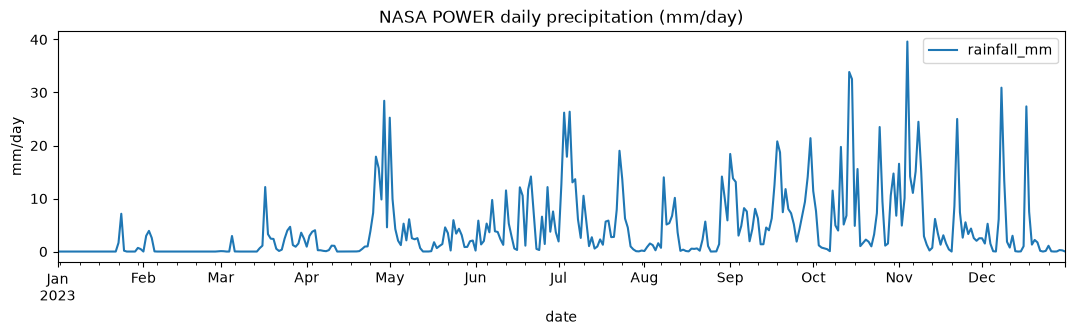

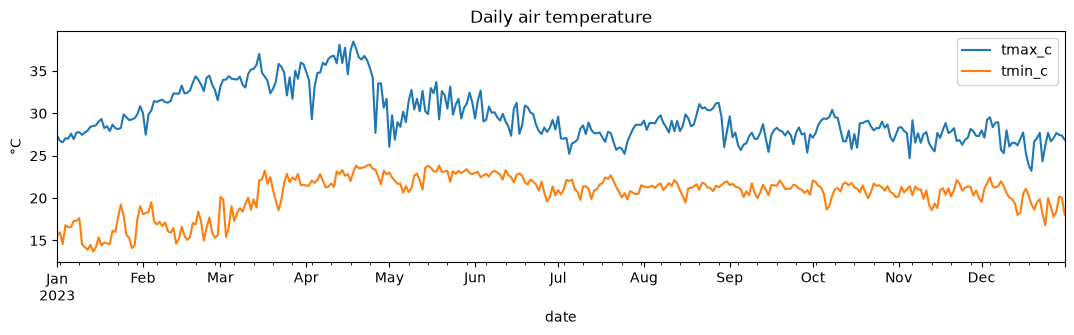

In [8]:
print("Shape:", weather.shape)
display(weather.isna().sum().rename("missing_values").to_frame())
display(weather.describe(include="all").T)
assert weather["date"].is_unique, "Duplicate dates found"
assert weather["rainfall_mm"].dropna().ge(0).all(), "Negative rainfall found"
weather.plot(x="date", y="rainfall_mm", figsize=(13, 3), title="NASA POWER daily precipitation (mm/day)")
plt.ylabel("mm/day")
plt.show()

weather.plot(x="date", y=["tmax_c", "tmin_c"], figsize=(13, 3), title="Daily air temperature")
plt.ylabel("°C")
plt.show()

## 6. FAO-56 Penman–Monteith reference evapotranspiration (ET₀)

Daily FAO-56 equation:

\[
ET_0 = \frac{0.408\Delta(R_n-G)+\gamma\frac{900}{T+273}u_2(e_s-e_a)}
{\Delta+\gamma(1+0.34u_2)}
\]

where:
- `ET₀`: reference evapotranspiration (mm/day)
- `Rn`: net radiation (MJ/m²/day)
- `G`: soil heat flux (often approximated as 0 for daily calculations)
- `T`: mean daily air temperature (°C)
- `u₂`: wind speed at 2 m (m/s)
- `es`, `ea`: saturation and actual vapour pressure (kPa)
- `Δ`: slope of saturation vapour-pressure curve (kPa/°C)
- `γ`: psychrometric constant (kPa/°C)

This implementation estimates net radiation using FAO-56 relationships and available solar radiation. Review units and missing-data handling carefully. If data quality is insufficient, do not pretend ET₀ is reliable.

,date,et0_mm_day
0,2023-01-01,3.606898
1,2023-01-02,3.497985
2,2023-01-03,3.338542
3,2023-01-04,3.258480
4,2023-01-05,3.335836


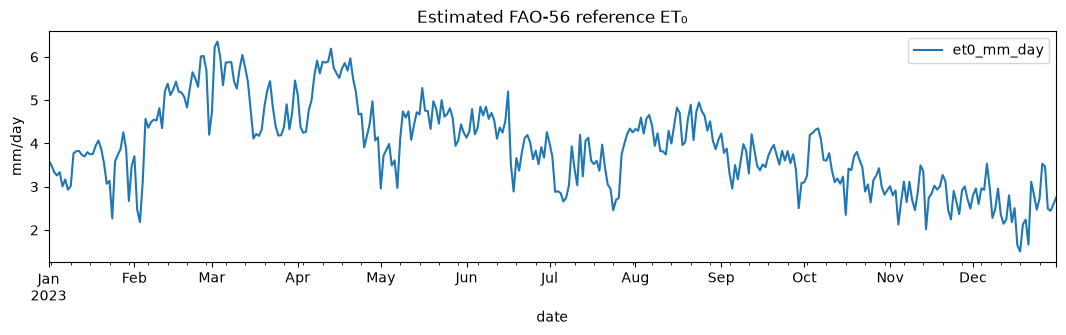

In [9]:
def saturation_vapour_pressure_kpa(temp_c):
    return 0.6108 * np.exp((17.27 * temp_c) / (temp_c + 237.3))

def fao56_et0_daily(row, latitude_deg=LATITUDE, elevation_m=ELEVATION_M):
    required = ["tmax_c", "tmin_c", "relative_humidity_pct",
                "wind_speed_m_s", "solar_radiation_mj_m2_day"]
    if any(pd.isna(row[k]) for k in required):
        return np.nan

    tmax, tmin = float(row["tmax_c"]), float(row["tmin_c"])
    rh = float(np.clip(row["relative_humidity_pct"], 0, 100))
    u2 = max(0.0, float(row["wind_speed_m_s"]))
    rs = max(0.0, float(row["solar_radiation_mj_m2_day"]))
    tmean = (tmax + tmin) / 2.0

    es = (saturation_vapour_pressure_kpa(tmax) +
          saturation_vapour_pressure_kpa(tmin)) / 2.0
    # Approximation when only daily mean RH is available.
    ea = (rh / 100.0) * es
    delta = 4098 * saturation_vapour_pressure_kpa(tmean) / ((tmean + 237.3) ** 2)
    pressure = 101.3 * (((293 - 0.0065 * elevation_m) / 293) ** 5.26)
    gamma = 0.000665 * pressure

    doy = pd.Timestamp(row["date"]).dayofyear
    phi = math.radians(latitude_deg)
    dr = 1 + 0.033 * math.cos(2 * math.pi / 365 * doy)
    solar_declination = 0.409 * math.sin(2 * math.pi / 365 * doy - 1.39)
    sunset_arg = float(np.clip(-math.tan(phi) * math.tan(solar_declination), -1, 1))
    ws = math.acos(sunset_arg)
    ra = (24 * 60 / math.pi) * 0.0820 * dr * (
        ws * math.sin(phi) * math.sin(solar_declination) +
        math.cos(phi) * math.cos(solar_declination) * math.sin(ws)
    )
    rso = (0.75 + 2e-5 * elevation_m) * ra
    rns = (1 - 0.23) * rs
    ratio = np.clip(rs / rso, 0, 1) if rso > 0 else 0
    rnl = 4.903e-9 * (((tmax + 273.16)**4 + (tmin + 273.16)**4) / 2) * (
        0.34 - 0.14 * math.sqrt(max(0, ea))
    ) * (1.35 * ratio - 0.35)
    rn = rns - rnl
    g = 0.0  # daily approximation
    numerator = 0.408 * delta * (rn - g) + gamma * (900 / (tmean + 273)) * u2 * (es - ea)
    denominator = delta + gamma * (1 + 0.34 * u2)
    return max(0.0, numerator / denominator) if denominator > 0 else np.nan

weather["et0_mm_day"] = weather.apply(fao56_et0_daily, axis=1)
display(weather[["date", "et0_mm_day"]].head())
weather.plot(x="date", y="et0_mm_day", figsize=(13, 3), title="Estimated FAO-56 reference ET₀")
plt.ylabel("mm/day")
plt.show()


## 7. Crop evapotranspiration: ETc = Kc × ET₀

FAO-56 crop-coefficient approach:

\[
ET_c = K_c \times ET_0
\]

`Kc` represents crop and management characteristics. **The value below is a provisional placeholder, not a verified coefficient for an 18-month-old East Coast Tall coconut palm.** It is deliberately exposed so you can replace it when a suitable coconut-specific source or field calibration is found.

Do not cite this placeholder as a literature value.

In [10]:
KC_PROVISIONAL = 0.70  # PLACEHOLDER ONLY: replace with a defensible young-coconut value
weather["etc_potential_mm_day_modelled"] = KC_PROVISIONAL * weather["et0_mm_day"]
print("Kc used:", KC_PROVISIONAL, "(provisional, not validated for this palm/stage)")
display(weather[["date", "et0_mm_day", "etc_potential_mm_day_modelled"]].head())

Kc used: 0.7 (provisional, not validated for this palm/stage)


,date,et0_mm_day,etc_potential_mm_day_modelled
0,2023-01-01,3.606898,2.524829
1,2023-01-02,3.497985,2.448589
2,2023-01-03,3.338542,2.336979
3,2023-01-04,3.258480,2.280936
4,2023-01-05,3.335836,2.335085


## 8. Soil-water balance and assumptions

Daily balance:

\[
S_t = \operatorname{clip}(S_{t-1} + P_e + I - ET_a - R - D,\ 0,\ S_{max})
\]

where `S` is available soil-water storage (mm), `Pe` is effective rainfall, `I` is irrigation, `ETa` is actual evapotranspiration, `R` is runoff, and `D` is drainage. `clip` constrains storage between zero and the assumed available storage capacity.

Available water in a root zone can be approximated as:

\[
TAW = (\theta_{FC}-\theta_{WP}) Z_r \times 1000
\]

where `θFC` and `θWP` are volumetric water contents (m³/m³) at field capacity and wilting point, and `Zr` is root-zone depth (m). This conversion is dimensional bookkeeping; the inputs must be appropriate for the site.

**All values below are placeholders**, not measured Coimbatore soil properties or validated coconut root-zone parameters.

In [11]:
SOIL = {
    "root_zone_depth_m": 0.45,                 # provisional assumption
    "field_capacity_vwc_m3_m3": 0.23,          # provisional assumption
    "wilting_point_vwc_m3_m3": 0.10,           # provisional assumption
    "initial_available_water_fraction": 0.70,  # initial condition assumption
    "runoff_fraction_of_rainfall": 0.05,       # simple placeholder, not calibrated
}
DEPLETION_TRIGGER = 0.50  # illustrative threshold only

fc = SOIL["field_capacity_vwc_m3_m3"]
wp = SOIL["wilting_point_vwc_m3_m3"]
zr = SOIL["root_zone_depth_m"]
TAW_MM = (fc - wp) * zr * 1000
print(f"Assumed TAW = {TAW_MM:.2f} mm")
print("This is calculated from provisional assumptions, not a measured soil value.")

Assumed TAW = 58.50 mm
This is calculated from provisional assumptions, not a measured soil value.


## 9. Run the water-balance model

This first pass uses no irrigation except a separate simulated irrigation-response scenario. The stress category is derived from the modelled depletion fraction, so it is **not an independent observed label**. A real implementation should calibrate effective rainfall, runoff, drainage, root-zone depth, crop coefficient and stress response against local measurements.

In [12]:
def simulate_scenario(weather_df, scenario="weather_only"):
    df = weather_df.sort_values("date").copy()
    storage = TAW_MM * SOIL["initial_available_water_fraction"]
    rows = []
    for _, row in df.iterrows():
        if pd.isna(row["rainfall_mm"]) or pd.isna(row["et0_mm_day"]):
            rows.append({**row.to_dict(), "model_status": "missing_required_weather"})
            continue

        rain = max(0.0, float(row["rainfall_mm"]))
        runoff = rain * SOIL["runoff_fraction_of_rainfall"]
        effective_rain = max(0.0, rain - runoff)
        irrigation = 0.0

        # Optional model test only; this is not a validated farm recommendation.
        if scenario == "irrigation_response" and storage < TAW_MM * (1 - DEPLETION_TRIGGER):
            irrigation = min(12.0, max(0.0, TAW_MM - storage - effective_rain))

        etc = float(row["etc_potential_mm_day_modelled"])
        relative_available = np.clip(storage / TAW_MM, 0, 1)
        ks = np.clip(relative_available / max(0.01, 1 - DEPLETION_TRIGGER), 0, 1)
        actual_et = etc * ks

        pre_drainage = storage + effective_rain + irrigation - actual_et
        # Report all above-capacity water as drainage so the bucket closes.
        drainage = max(0.0, pre_drainage - TAW_MM)
        storage = float(np.clip(pre_drainage - drainage, 0, TAW_MM))
        depletion = 1 - storage / TAW_MM
        stress = "low" if depletion < 0.30 else ("moderate" if depletion < DEPLETION_TRIGGER else "high")
        action = (
            "continue_monitoring" if stress == "low" else
            "recheck_soil_and_weather" if stress == "moderate" else
            "consider_irrigation_if_field_conditions_confirm"
        )
        simulated_vwc = wp + (storage / TAW_MM) * (fc - wp)

        rows.append({
            **row.to_dict(),
            "scenario": scenario,
            "effective_rainfall_mm_modelled": effective_rain,
            "runoff_mm_modelled": runoff,
            "irrigation_mm_simulated": irrigation,
            "actual_et_mm_day_modelled": actual_et,
            "drainage_mm_modelled": drainage,
            "soil_water_storage_mm_modelled": storage,
            "depletion_fraction_modelled": depletion,
            "soil_moisture_vwc_pct_simulated": simulated_vwc * 100,
            "water_stress_rule_derived": stress,
            "recommended_action_simulated": action,
            "model_status": "computed_using_provisional_parameters",
        })
    result = pd.DataFrame(rows)
    result["location"] = LOCATION
    result["latitude"] = LATITUDE
    result["longitude"] = LONGITUDE
    result["variety"] = VARIETY
    result["palm_age_months"] = PALM_AGE_MONTHS
    result["data_class"] = "NASA_POWER_weather_plus_modelled_outputs"
    result["stress_label_status"] = "rule_derived_not_ground_truth"
    return result

model_df = simulate_scenario(weather, scenario="weather_only")
model_df.to_csv(OUT_DIR / "stage1_hybrid_dataset.csv", index=False)
display(model_df[["date", "rainfall_mm", "et0_mm_day", "soil_water_storage_mm_modelled",
                  "soil_moisture_vwc_pct_simulated", "water_stress_rule_derived"]].head())
print("Saved:", OUT_DIR / "stage1_hybrid_dataset.csv")

,date,rainfall_mm,et0_mm_day,soil_water_storage_mm_modelled,soil_moisture_vwc_pct_simulated,water_stress_rule_derived
0,2023-01-01,0.0,3.606898,38.425171,18.538927,moderate
1,2023-01-02,0.0,3.497985,35.976582,17.994796,moderate
2,2023-01-03,0.0,3.338542,33.639603,17.475467,moderate
3,2023-01-04,0.0,3.258480,31.358667,16.968593,moderate
4,2023-01-05,0.0,3.335836,29.023581,16.449685,high


Saved: cococare_stage1_outputs/stage1_hybrid_dataset.csv


## 10. Visualize and check model behaviour

These plots show what the current equations produce. They are diagnostic plots, not evidence of agronomic accuracy.

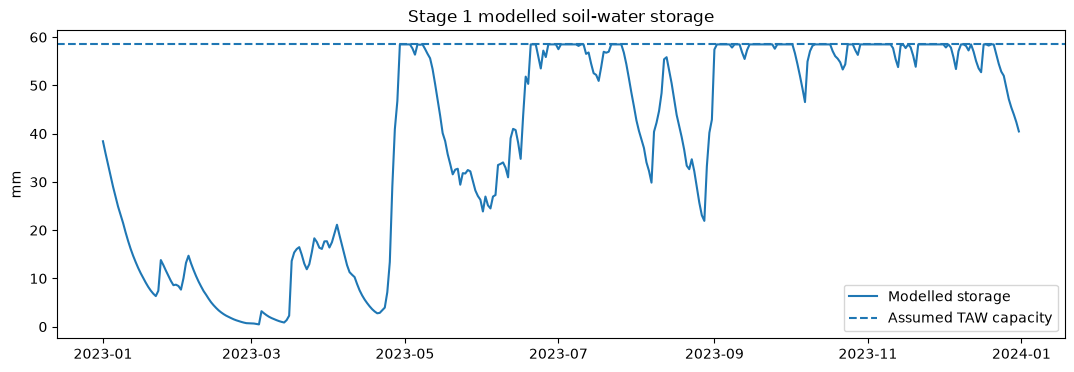

,days
water_stress_rule_derived,
low,197
high,125
moderate,43


,rainfall_mm,et0_mm_day,soil_water_storage_mm_modelled,soil_moisture_vwc_pct_simulated
count,365.000000,365.000000,365.000000,365.000000
mean,4.334712,3.925038,38.087004,18.463779
std,6.458638,0.981208,21.355240,4.745609
min,0.000000,1.501909,0.473303,10.105179
25%,0.070000,3.128287,16.127752,13.583945
50%,1.570000,3.872973,46.768195,20.392932
75%,5.830000,4.575454,58.500000,23.000000
max,39.610000,6.353284,58.500000,23.000000


In [13]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(model_df["date"], model_df["soil_water_storage_mm_modelled"], label="Modelled storage")
ax.axhline(TAW_MM, linestyle="--", label="Assumed TAW capacity")
ax.set_title("Stage 1 modelled soil-water storage")
ax.set_ylabel("mm")
ax.legend()
plt.show()

display(model_df["water_stress_rule_derived"].value_counts(dropna=False).rename("days").to_frame())
display(model_df[["rainfall_mm", "et0_mm_day", "soil_water_storage_mm_modelled",
                  "soil_moisture_vwc_pct_simulated"]].describe())

## 11. TNAU reference rules: keep source evidence separate

TNAU's online guidance includes:
- **Young palm irrigation:** first two years, 45 litres per seedling once every four days during dry summer months (check applicability and local conditions).
- **Tamil Nadu nutrient guidance:** the page lists second-year recommendations, including 20 kg compost/palm/year and nutrient/fertilizer quantities. Verify the table, units, fertilizer form, timing and conditions directly before encoding rules.

These are *recommendations*, not actual applications recorded at a farm. Do not mix them into the weather dataset as if they were measured values. Keep them in a separate reference table and record the exact URL, section/table, access date, units, and applicability notes.

In [14]:
tnau_rules = pd.DataFrame([
    {
        "topic": "young_palm_irrigation",
        "age_category": "first two years after planting",
        "recommendation_summary": "TNAU page states 45 L/seedling once every 4 days during dry summer months",
        "numeric_value": 45,
        "unit": "L/seedling/application",
        "conditions": "dry summer months; verify local applicability and method",
        "source_url": TNAU_IRRIGATION_URL,
        "source_type": "official_extension_guidance",
        "status": "source_summary_to_verify_before_use",
    },
    {
        "topic": "second_year_compost",
        "age_category": "second year after planting",
        "recommendation_summary": "TNAU table lists compost recommendation for second year",
        "numeric_value": 20,
        "unit": "kg/palm/year",
        "conditions": "verify exact table and management context on official page",
        "source_url": TNAU_NUTRIENT_URL,
        "source_type": "official_extension_guidance",
        "status": "source_summary_to_verify_before_use",
    },
])
tnau_rules.to_csv(OUT_DIR / "tnau_reference_rules.csv", index=False)
display(tnau_rules)

,topic,age_category,recommendation_summary,numeric_value,unit,conditions,source_url,source_type,status
0,young_palm_irrigation,first two years after planting,TNAU page states 45 L/seedling once every 4 da...,45,L/seedling/application,dry summer months; verify local applicability ...,https://www.agritech.tnau.ac.in/expert_system/...,official_extension_guidance,source_summary_to_verify_before_use
1,second_year_compost,second year after planting,TNAU table lists compost recommendation for se...,20,kg/palm/year,verify exact table and management context on o...,https://agritech.tnau.ac.in/expert_system/coco...,official_extension_guidance,source_summary_to_verify_before_use


## 12. Export source and parameter metadata

This metadata file is essential for reproducibility and for the Methods section of a paper.

In [ ]:
metadata = {
    "project": "CocoCare",
    "stage": "Stage 1",
    "variety": VARIETY,
    "palm_age_months": PALM_AGE_MONTHS,
    "location": LOCATION,
    "coordinates": {"latitude": LATITUDE, "longitude": LONGITUDE, "elevation_m_approx": ELEVATION_M},
    "weather_source": "NASA POWER daily point API",
    "weather_source_url": "https://power.larc.nasa.gov/docs/services/api/temporal/daily/",
    "weather_period": {"start": START_DATE, "end": END_DATE},
    "agronomic_sources": {
        "TNAU irrigation": TNAU_IRRIGATION_URL,
        "TNAU nutrient management": TNAU_NUTRIENT_URL,
        "FAO-56 ET0": FAO56_ET0_URL,
    },
    
    "formulas": {
        "ETc": "ETc = Kc * ET0 (FAO-56 crop coefficient approach)",
        "TAW": "TAW = (field_capacity_vwc - wilting_point_vwc) * root_zone_depth_m * 1000",
        "effective_rainfall": "P_eff = max(0, rainfall - runoff)",
        "water_balance": (
            "S_t = clip(S_(t-1) + effective_rainfall "
            "+ irrigation - actual_ET - drainage, 0, TAW)"
        ),
    },

    
    "provisional_parameters": {
        **SOIL,
        "kc_provisional": KC_PROVISIONAL,
        "depletion_trigger_fraction": DEPLETION_TRIGGER,
        "total_available_water_mm_calculated": float(TAW_MM),
        "status": (
            "Prototype assumptions; require literature support, "
            "soil data, or field calibration before agronomic use."
        ),
    },

    "limitations": [
        "NASA POWER is gridded weather data, not an on-farm sensor observation.",
        "Soil and crop parameters are provisional and require evidence or calibration.",
        "Modelled moisture and stress labels are not ground truth.",
        "The notebook's stress labels are derived from the same water-balance model being tested.",
        "No agronomic accuracy claim is justified without independent field validation."
    ],
}
(OUT_DIR / "stage1_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved metadata:", OUT_DIR / "stage1_metadata.json")
print("Outputs folder:", OUT_DIR.resolve())

Saved metadata: cococare_stage1_outputs/stage1_metadata.json
Outputs folder: /home/sivabharathi/Documents/FinalYearProject/CocoCare/ml/data/coconut_health/CocoCare_Stage1_Hybrid_Notebook/cococare_stage1_outputs


## 13. Suggested paper/literature-review structure

Use this notebook to document the **Methods** section, but do not treat code-generated results as validated agronomic findings.

Suggested structure:
1. Study context: Stage 1 East Coast Tall, 18 months, Coimbatore.
2. Weather source and spatial/temporal resolution (NASA POWER; coordinates; date range; variables).
3. Agronomic guidance source (TNAU; age category; irrigation and fertilizer recommendation tables).
4. Model equations (FAO-56 ET₀; ETc = Kc × ET₀; root-zone water balance).
5. Parameter provenance table (value, unit, source, whether measured/assumed/calibrated).
6. Synthetic-data generation and scenario definitions.
7. Validation plan: compare modelled moisture with calibrated sensor observations; compare irrigation decisions with agronomist-reviewed criteria.
8. Limitations and uncertainty.

### Citation note
For a formal paper, cite the original FAO-56 document (Allen, Pereira, Raes & Smith, 1998), NASA POWER documentation, and the exact TNAU page/table accessed. For any coconut-specific Kc or root-zone parameter, find and cite a study or agronomic reference that matches the palm age, variety, climate and irrigation context. Do not cite the provisional values in this notebook as literature values.

## 14. Troubleshooting

- **NASA API request fails:** check internet access, date format, and whether the requested period is available.
- **Missing weather values:** inspect the relevant column; do not automatically fill rainfall with zero.
- **Negative or implausible ET₀:** check parameter units, solar-radiation availability, humidity assumptions, coordinates and elevation.
- **Storage remains at zero or capacity for long periods:** inspect Kc, initial storage, soil capacity, rainfall, runoff and drainage assumptions.
- **Model labels look convincing:** remember labels are generated from model rules; they do not validate the model.
- **For paper-quality results:** use a documented historical period, save the raw download and metadata, pin package versions, and compare with field observations where possible.
